# EDA - Thong ke mo ta va phat hien outlier

Chay Phan 0 truoc. Sau do cac phan 1-9 co the chay rieng le.

In [ ]:
# Phan 0 - Thu vien, duong dan, nap du lieu
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os
sns.set_style("whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"
OUT_DIR="eda_stats_charts"
os.makedirs(OUT_DIR,exist_ok=True)
DATA_FILE="dataset_cement_cust.xlsx"
data_path = DATA_FILE
if not os.path.isfile(data_path):
    downloads_path = os.path.join(os.path.expanduser("~"), "Downloads", DATA_FILE) ## FILE RAW LƯU Ở PHẦN DOWNLOADS CỦA MÁY TÍNH, NẾU KHÔNG CÓ THÌ BÁO LỖI
    if os.path.isfile(downloads_path):
        data_path = downloads_path
    else:
        raise FileNotFoundError(
            f"Cannot find {DATA_FILE!r}. Put the file in the notebook's working "
            f"folder or Downloads, or set DATA_FILE to its full path. "
            f"Working folder: {os.getcwd()}"
        )

df = pd.read_excel(data_path)

numeric_cols=df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols=df.select_dtypes(include=["object"]).columns.tolist()
print(f"Da nap {df.shape[0]} NPP, {df.shape[1]} bien")
print(numeric_cols)
print(categorical_cols)

Da nap 240 NPP, 21 bien
['Doanh_so_12_thang_tan', 'So_diem_ban', 'Do_phu_thi_truong_pct', 'Gia_ban_trung_binh_NPP_VND_tan', 'Gia_TB_thi_truong_khu_vuc_VND_tan', 'Price_Index', 'Cuong_do_canh_tranh_1_5', 'Bien_loi_nhuan_gop_NPP_pct', 'Bien_loi_nhuan_TB_doi_thu_pct', 'Profitability_Gap_pct', 'So_nam_hop_tac', 'Share_of_Wallet_pct', 'Tang_truong_YoY_pct', 'Diem_du_an_ha_tang_khu_vuc_1_5', 'Vong_quay_ton_kho_ngay', 'Ty_le_cong_no_qua_han_pct', 'Muc_rebate_hien_tai_VND_tan']
['NPP_ID', 'Tinh_Thanh', 'Vung_Mien', 'Loai_NPP']


In [3]:
# Phan 1 - Thong ke mo ta bien dinh luong
desc_rows=[]
for col in numeric_cols:
    s=df[col].dropna(); mode_val=s.mode().iloc[0] if not s.mode().empty else np.nan
    cv=(s.std()/s.mean()*100) if s.mean()!=0 else np.nan
    desc_rows.append({"Bien":col,"N":s.count(),"Mean":s.mean(),"Median":s.median(),"Mode":mode_val,"Std":s.std(),"Min":s.min(),"Max":s.max(),"Range":s.max()-s.min(),"Skewness":stats.skew(s),"Kurtosis":stats.kurtosis(s),"CV_pct":cv})
desc_df=pd.DataFrame(desc_rows).round(2)
display(desc_df)
desc_df.to_csv(f"{OUT_DIR}/descriptive_stats.csv",index=False,encoding="utf-8-sig")

,Bien,N,Mean,Median,Mode,Std,Min,Max,Range,Skewness,Kurtosis,CV_pct
0,Doanh_so_12_thang_tan,240,23212.92,19879.50,4636.00,13512.99,4636.00,93439.00,88803.00,1.56,3.63,58.21
1,So_diem_ban,240,52.14,47.00,48.00,26.11,5.00,183.00,178.00,1.28,2.89,50.08
2,Do_phu_thi_truong_pct,240,29.87,29.20,10.00,11.96,10.00,72.70,62.70,0.46,0.15,40.05
3,Gia_ban_trung_binh_NPP_VND_tan,240,1513150.00,1509000.00,1457000.00,43500.04,1414000.00,1611000.00,197000.00,0.08,-0.86,2.87
4,Gia_TB_thi_truong_khu_vuc_VND_tan,240,1517395.83,1515000.00,1502000.00,32159.08,1454000.00,1594000.00,140000.00,0.09,-0.74,2.12
5,Price_Index,240,1.00,1.00,1.00,0.01,0.96,1.04,0.07,-0.04,-0.46,1.48
6,Cuong_do_canh_tranh_1_5,240,3.25,3.20,3.10,0.92,1.00,5.00,4.00,-0.18,-0.45,28.38
7,Bien_loi_nhuan_gop_NPP_pct,240,9.01,9.05,5.91,2.57,3.48,15.62,12.14,0.14,-0.37,28.55
8,Bien_loi_nhuan_TB_doi_thu_pct,240,9.36,9.36,9.46,1.23,6.50,13.06,6.56,0.06,-0.06,13.12
9,Profitability_Gap_pct,240,-0.36,-0.48,-0.68,1.89,-5.50,3.79,9.29,0.08,-0.57,-526.81


In [4]:
# Phan 2 - Tan suat bien dinh tinh
for col in categorical_cols:
    if col=="NPP_ID": continue
    freq_df=pd.DataFrame({"So_luong":df[col].value_counts(),"Ty_le_pct":(df[col].value_counts(normalize=True)*100).round(1)})
    print(f"\n--- {col} ---"); display(freq_df.head(15))
    safe=col.replace("/","_").replace("\\","_").replace(" ","_")
    freq_df.to_csv(f"{OUT_DIR}/frequency_{safe}.csv",encoding="utf-8-sig")


--- Tinh_Thanh ---


,So_luong,Ty_le_pct
Tinh_Thanh,,
Bình Phước,27,11.2
Bà Rịa - Vũng Tàu,19,7.9
TP.HCM,18,7.5
Tây Ninh,18,7.5
Đồng Nai,17,7.1
Bình Thuận,16,6.7
Sóc Trăng,15,6.2
Bình Dương,14,5.8
Tiền Giang,11,4.6



--- Vung_Mien ---


,So_luong,Ty_le_pct
Vung_Mien,,
Đông Nam Bộ,129,53.8
Tây Nam Bộ (ĐBSCL),111,46.2



--- Loai_NPP ---


,So_luong,Ty_le_pct
Loai_NPP,,
Nhà phân phối cấp 1,155,64.6
Tổng đại lý,85,35.4


In [5]:
# Phan 3 - Outlier IQR va Z-score
key_vars=["Doanh_so_12_thang_tan","Muc_rebate_hien_tai_VND_tan","Profitability_Gap_pct","Bien_loi_nhuan_gop_NPP_pct","Ty_le_cong_no_qua_han_pct","Price_Index","Vong_quay_ton_kho_ngay","Share_of_Wallet_pct","So_diem_ban"]
outlier_summary=[]; outlier_detail={}
for col in key_vars:
    s=df[col]; q1,q3=s.quantile(.25),s.quantile(.75); iqr=q3-q1; lower,upper=q1-1.5*iqr,q3+1.5*iqr
    im=(s<lower)|(s>upper); z=np.abs(stats.zscore(s,nan_policy="omit")); zm=z>3
    outlier_summary.append({"Bien":col,"So_outlier_IQR":im.sum(),"Ty_le_IQR_pct":round(im.sum()/len(s)*100,1),"Nguong_duoi_IQR":round(lower,2),"Nguong_tren_IQR":round(upper,2),"So_outlier_Zscore":np.nansum(zm)})
    if im.sum()>0:
        detail=df.loc[im,["NPP_ID","Tinh_Thanh",col]].sort_values(col); outlier_detail[col]=detail
        safe=col.replace("/","_").replace("\\","_").replace(" ","_"); detail.to_csv(f"{OUT_DIR}/outlier_detail_{safe}.csv",index=False,encoding="utf-8-sig")
outlier_df=pd.DataFrame(outlier_summary); display(outlier_df)
outlier_df.to_csv(f"{OUT_DIR}/outlier_summary.csv",index=False,encoding="utf-8-sig")

,Bien,So_outlier_IQR,Ty_le_IQR_pct,Nguong_duoi_IQR,Nguong_tren_IQR,So_outlier_Zscore
0,Doanh_so_12_thang_tan,10,4.2,-8383.50,51104.50,3
1,Muc_rebate_hien_tai_VND_tan,0,0.0,-2500.00,97500.00,0
2,Profitability_Gap_pct,0,0.0,-6.03,5.24,0
3,Bien_loi_nhuan_gop_NPP_pct,0,0.0,1.99,16.00,0
4,Ty_le_cong_no_qua_han_pct,11,4.6,-3.41,12.29,4
5,Price_Index,1,0.4,0.96,1.04,0
6,Vong_quay_ton_kho_ngay,4,1.7,1.41,49.11,0
7,Share_of_Wallet_pct,1,0.4,13.66,78.36,0
8,So_diem_ban,7,2.9,-9.00,111.00,3


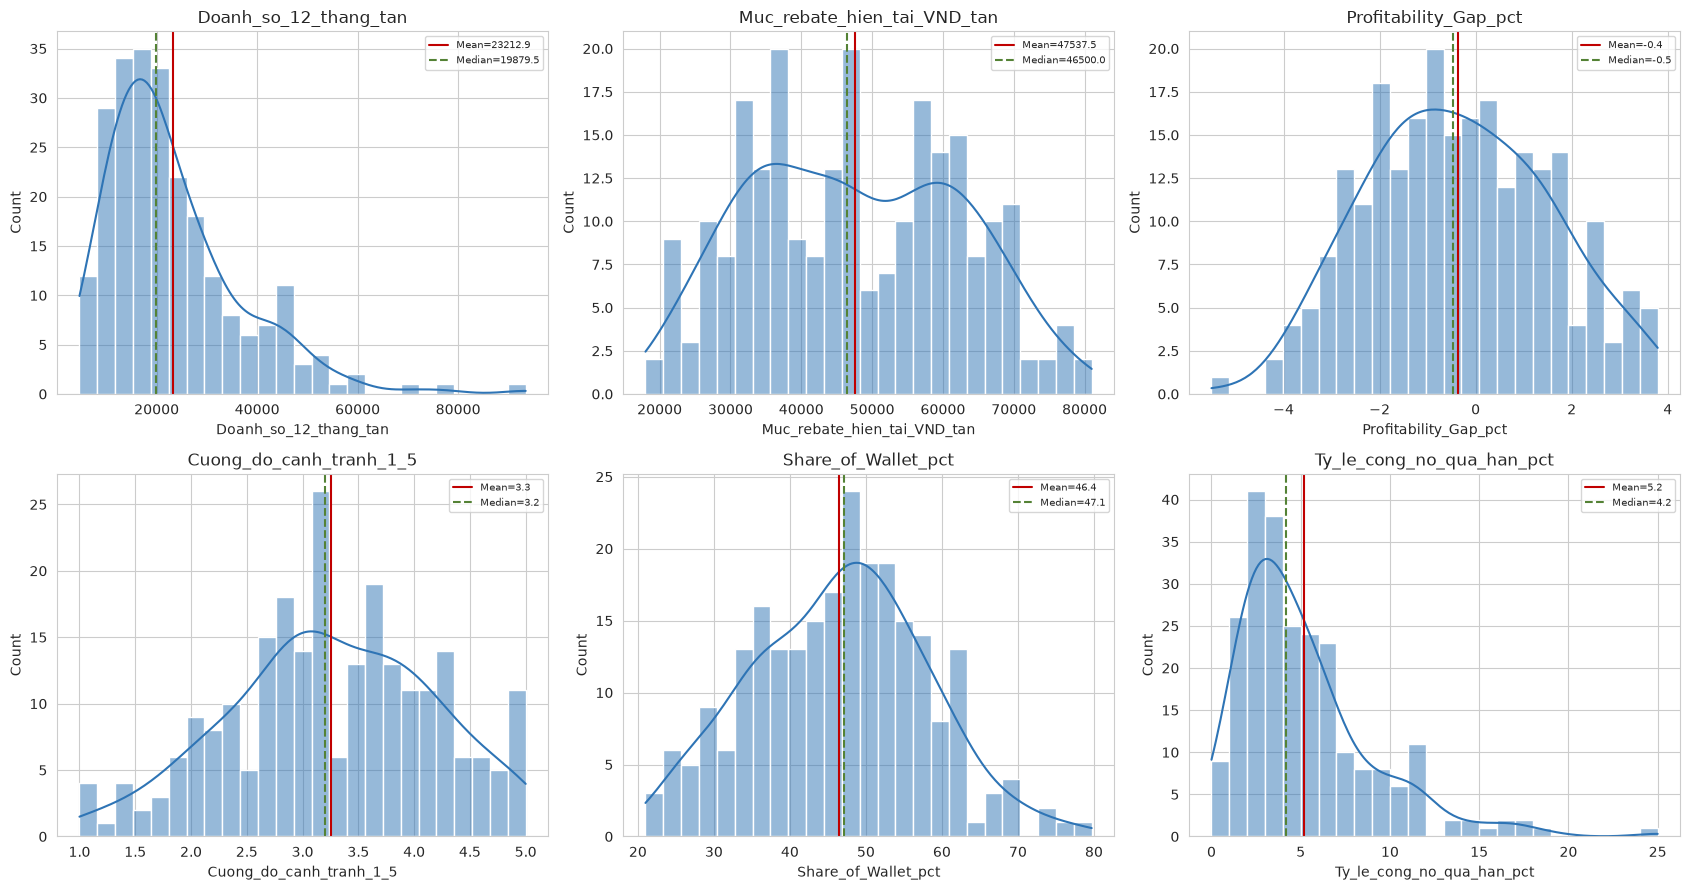

In [6]:
# Phan 4 - Histogram
hist_vars=["Doanh_so_12_thang_tan","Muc_rebate_hien_tai_VND_tan","Profitability_Gap_pct","Cuong_do_canh_tranh_1_5","Share_of_Wallet_pct","Ty_le_cong_no_qua_han_pct"]
fig,axes=plt.subplots(2,3,figsize=(17,9))
for ax,col in zip(axes.flat,hist_vars):
 s=df[col]; sns.histplot(s,bins=25,color="#2E74B5",ax=ax,kde=True); ax.axvline(s.mean(),color="#C00000",label=f"Mean={s.mean():.1f}"); ax.axvline(s.median(),color="#548235",linestyle="--",label=f"Median={s.median():.1f}"); ax.set_title(col); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/01_histograms.png",dpi=150,bbox_inches="tight"); plt.show()

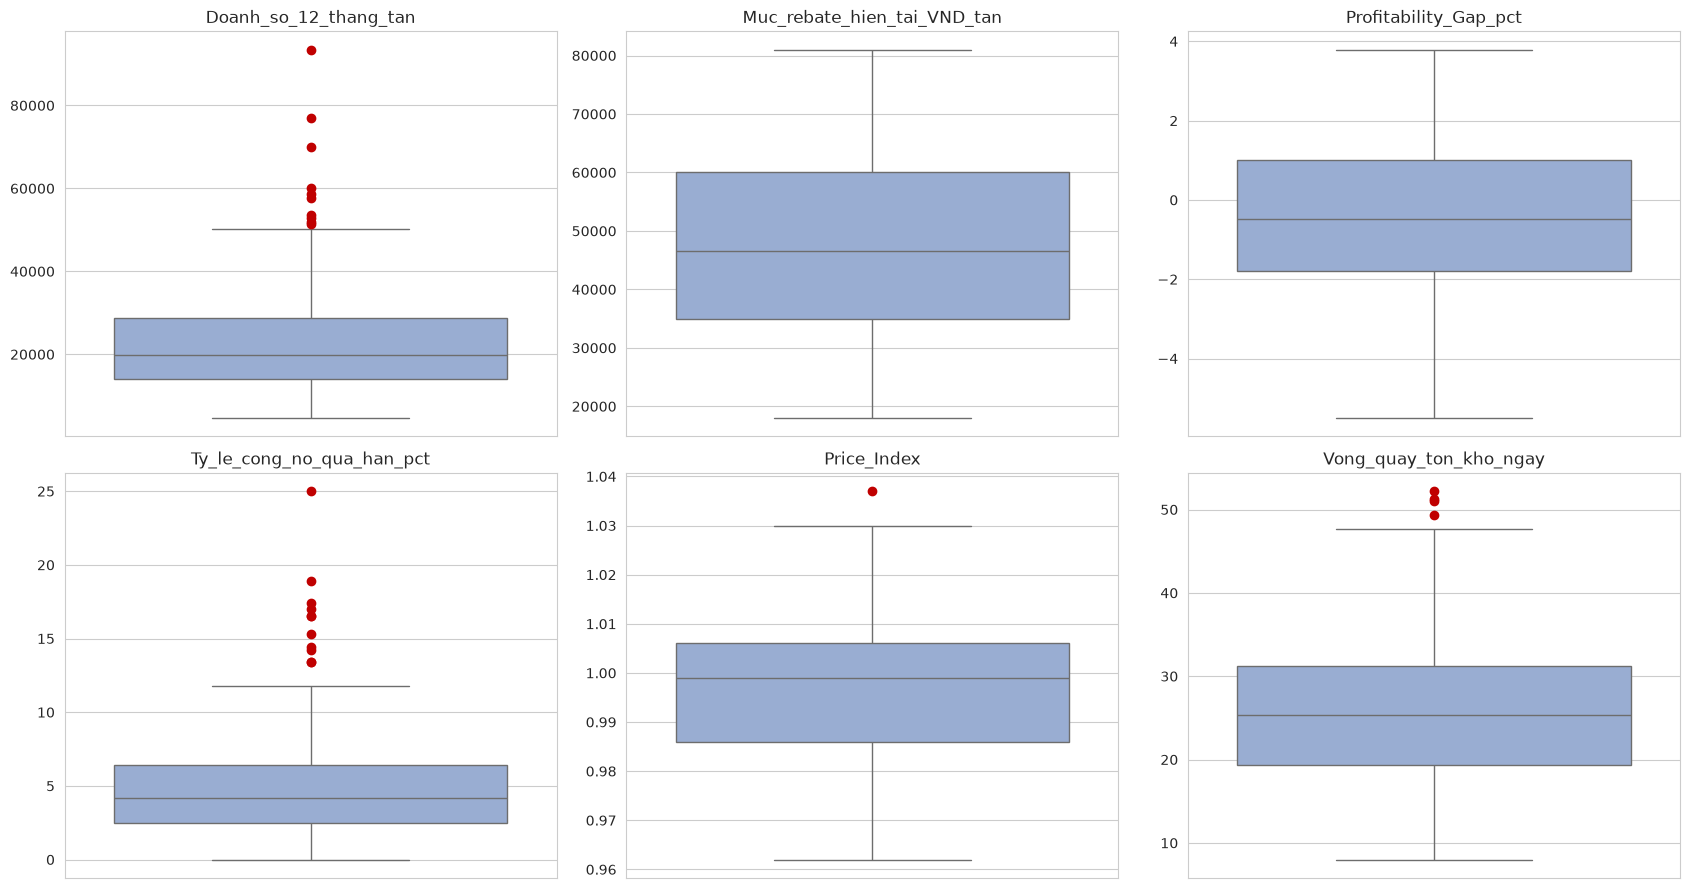

In [7]:
# Phan 5 - Boxplot outlier
box_vars=["Doanh_so_12_thang_tan","Muc_rebate_hien_tai_VND_tan","Profitability_Gap_pct","Ty_le_cong_no_qua_han_pct","Price_Index","Vong_quay_ton_kho_ngay"]
fig,axes=plt.subplots(2,3,figsize=(17,9))
for ax,col in zip(axes.flat,box_vars): sns.boxplot(y=df[col],ax=ax,color="#8FAADC",flierprops={"markerfacecolor":"#C00000","markeredgecolor":"#C00000","markersize":6}); ax.set_title(col); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/02_boxplots.png",dpi=150,bbox_inches="tight"); plt.show()

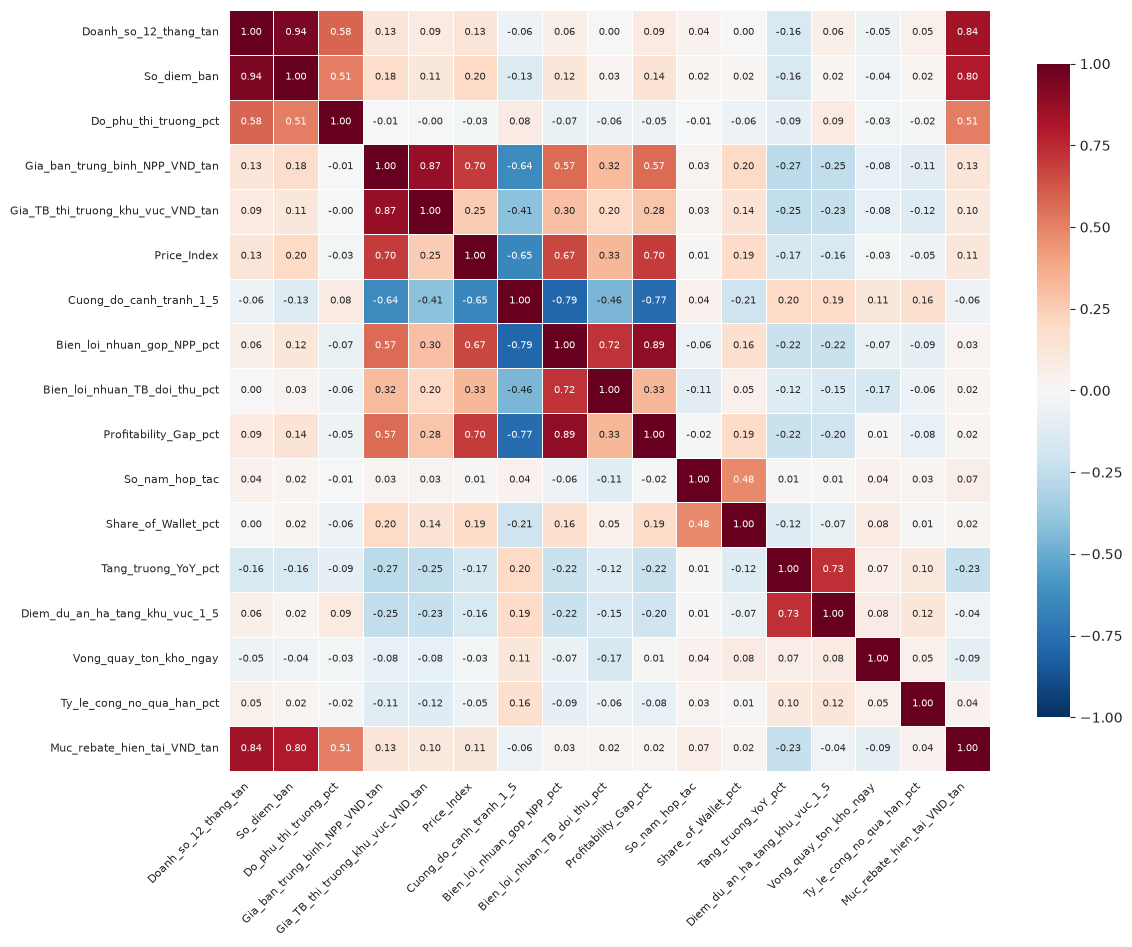

In [8]:
# Phan 6 - Ma tran tuong quan
corr_matrix=df[numeric_cols].corr().round(2); corr_matrix.to_csv(f"{OUT_DIR}/correlation_matrix.csv",encoding="utf-8-sig")
plt.figure(figsize=(12,10)); sns.heatmap(corr_matrix,annot=True,fmt=".2f",cmap="RdBu_r",center=0,vmin=-1,vmax=1,square=True,linewidths=.5,annot_kws={"size":7},cbar_kws={"shrink":.8}); plt.xticks(rotation=45,ha="right",fontsize=8); plt.yticks(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/03_correlation_heatmap.png",dpi=150,bbox_inches="tight"); plt.show()

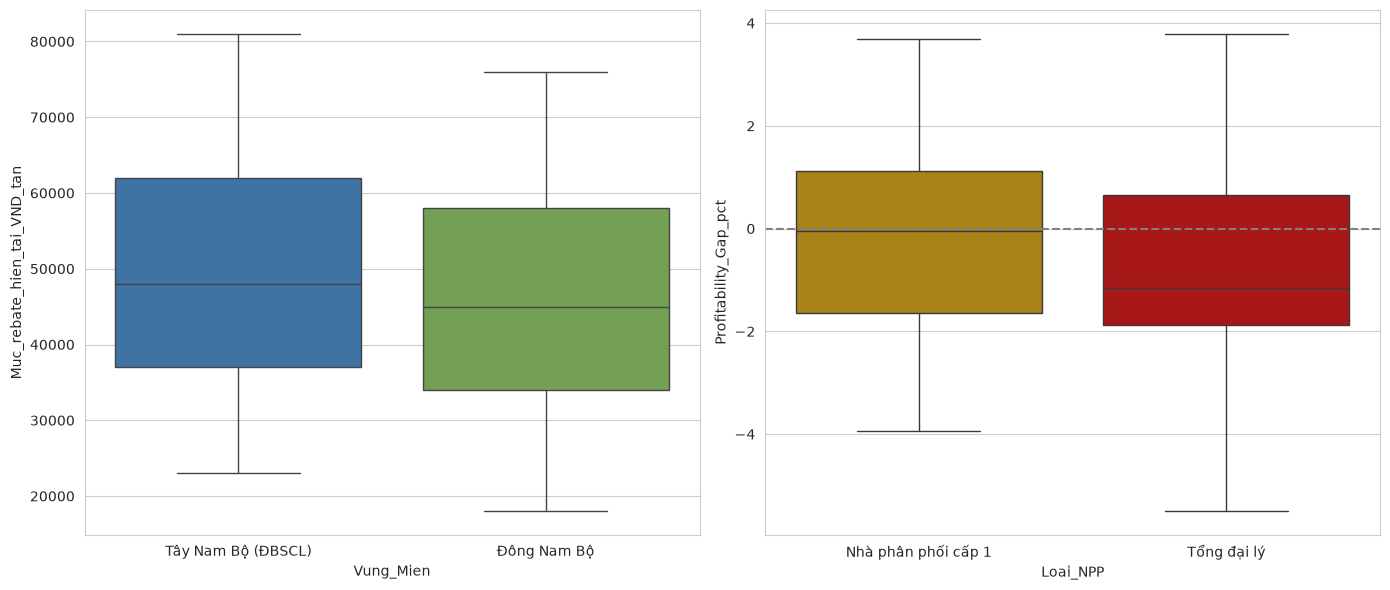

In [9]:
# Phan 7 - So sanh Vung mien va Loai NPP
fig,axes=plt.subplots(1,2,figsize=(14,6)); sns.boxplot(data=df,x="Vung_Mien",y="Muc_rebate_hien_tai_VND_tan",hue="Vung_Mien",palette=["#2E74B5","#70AD47"],legend=False,ax=axes[0]); sns.boxplot(data=df,x="Loai_NPP",y="Profitability_Gap_pct",hue="Loai_NPP",palette=["#BF8F00","#C00000"],legend=False,ax=axes[1]); axes[1].axhline(0,color="grey",linestyle="--"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/04_group_comparison.png",dpi=150,bbox_inches="tight"); plt.show()

,So_luong,Profit_Gap_TB,Rebate_hien_tai_TB
Nhom_canh_tranh,,,
Canh tranh thap (<=2.5),52,1.70,50096.15
Canh tranh cao (>2.5),188,-0.93,46829.79


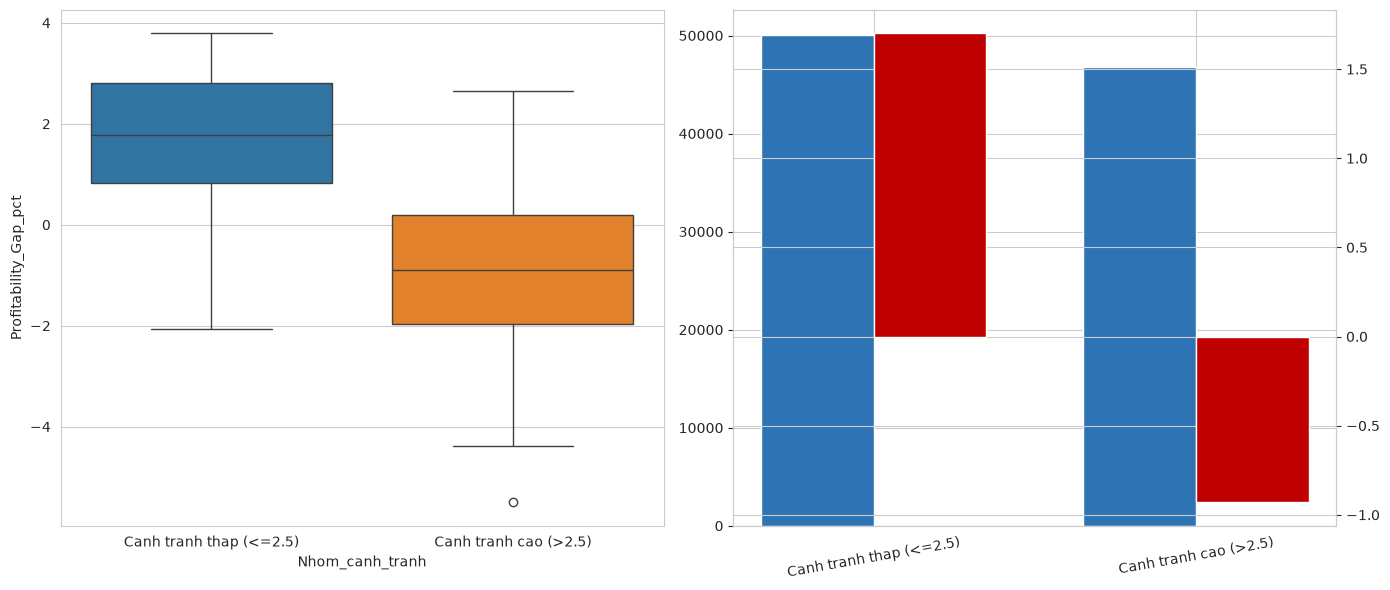

In [10]:
# Phan 8 - Nhom cuong do canh tranh
df["Nhom_canh_tranh"]=pd.cut(df["Cuong_do_canh_tranh_1_5"],bins=[0,2.5,5],labels=["Canh tranh thap (<=2.5)","Canh tranh cao (>2.5)"])
group_stats=df.groupby("Nhom_canh_tranh",observed=True).agg(So_luong=("NPP_ID","count"),Profit_Gap_TB=("Profitability_Gap_pct","mean"),Rebate_hien_tai_TB=("Muc_rebate_hien_tai_VND_tan","mean")).round(2); display(group_stats); group_stats.to_csv(f"{OUT_DIR}/business_group_stats.csv",encoding="utf-8-sig")
fig,axes=plt.subplots(1,2,figsize=(14,6)); sns.boxplot(data=df,x="Nhom_canh_tranh",y="Profitability_Gap_pct",hue="Nhom_canh_tranh",legend=False,ax=axes[0]); x=np.arange(len(group_stats)); w=.35; ax2=axes[1].twinx(); b1=axes[1].bar(x-w/2,group_stats["Rebate_hien_tai_TB"],w,label="Rebate TB",color="#2E74B5"); b2=ax2.bar(x+w/2,group_stats["Profit_Gap_TB"],w,label="Profit Gap TB",color="#C00000"); axes[1].set_xticks(x); axes[1].set_xticklabels(group_stats.index,rotation=10); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/06_nghich_ly_canh_tranh.png",dpi=150,bbox_inches="tight"); plt.show()

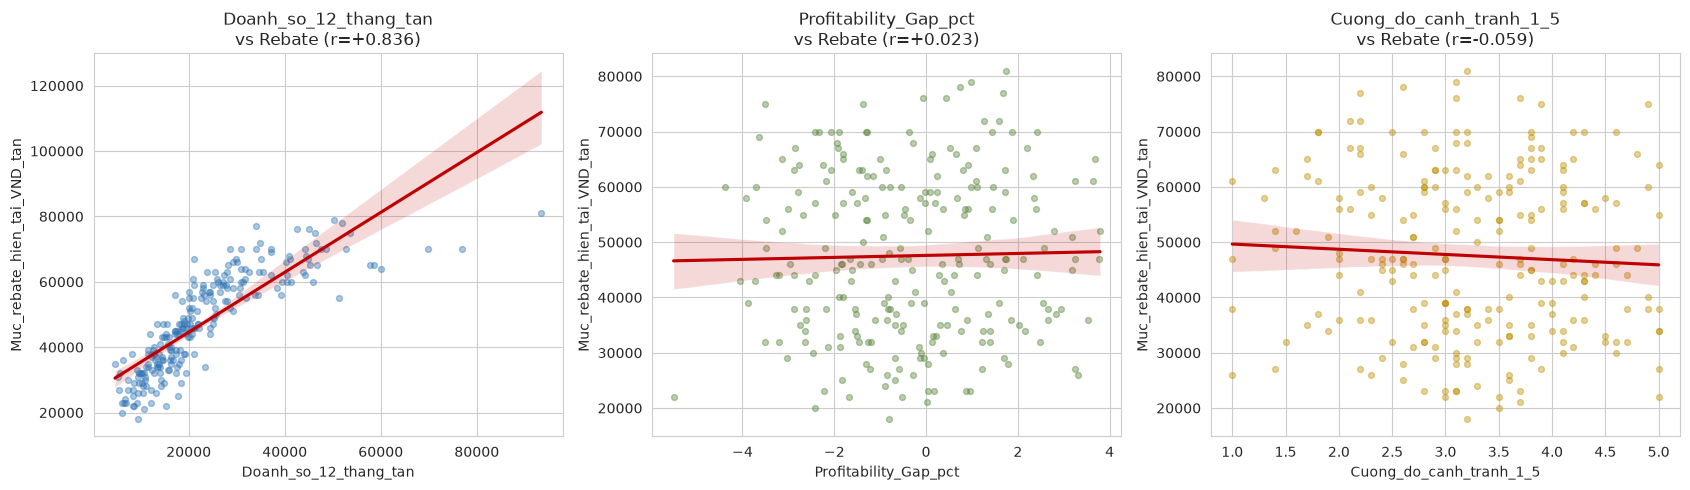

In [11]:
# Phan 9 - Scatter cac driver cua Rebate
pairs=[("Doanh_so_12_thang_tan","Muc_rebate_hien_tai_VND_tan","#2E74B5"),("Profitability_Gap_pct","Muc_rebate_hien_tai_VND_tan","#548235"),("Cuong_do_canh_tranh_1_5","Muc_rebate_hien_tai_VND_tan","#BF8F00")]
fig,axes=plt.subplots(1,3,figsize=(17,5))
for ax,(x,y,color) in zip(axes,pairs):
 r=df[x].corr(df[y]); sns.regplot(data=df,x=x,y=y,scatter_kws={"alpha":.4,"s":18,"color":color},line_kws={"color":"#C00000"},ax=ax); ax.set_title(f"{x}\nvs Rebate (r={r:+.3f})")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/05_scatter_rebate_drivers.png",dpi=150,bbox_inches="tight"); plt.show()